In [ ]:
from pydantic import BaseModel
from langgraph.graph import StateGraph, START, END

In [6]:
class GreetState(BaseModel):
    message:str = ""

In [7]:
graph = StateGraph(GreetState)

In [12]:
def Greet(state: GreetState):
    state.message = f"{state.message} ! all ! good"
    return state

def upperCase(state: GreetState):
    state.message = state.message.upper()
    return state

In [14]:
graph.add_node("greet", Greet)

In [15]:
graph.add_node("upper_name", upperCase)

In [16]:
graph.add_edge(START, "greet")
graph.add_edge("greet", "upper_name")
graph.add_edge("upper_name", END)

In [17]:
finalGraph = graph.compile()

In [18]:
res = finalGraph.invoke({"message": "I love LangGraph !"})

In [19]:
res

{'message': 'I LOVE LANGGRAPH ! ! ALL ! GOOD'}

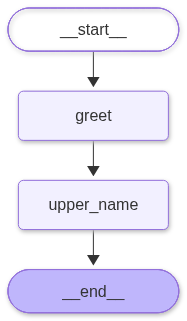

In [20]:
from IPython.display import Image
Image(finalGraph.get_graph().draw_mermaid_png())